# 🚕 Q-Learning en Taxi-v4 — Trabajo en casa

En este ejercicio aplicará Q-Learning al ambiente **Taxi-v4** de Gymnasium.

La lógica es la misma trabajada en FrozenLake:

$$
(s_t,a_t) \rightarrow (r_{t+1},s_{t+1})
$$

y la actualización:

$$
Q(s_t,a_t)
\leftarrow
Q(s_t,a_t)
+
\alpha
\left[
r_{t+1}
+
\gamma \max_a Q(s_{t+1},a)
-
Q(s_t,a_t)
\right]
$$

## Objetivo

Implementar y analizar un agente Q-Learning capaz de aprender a recoger un pasajero y llevarlo a su destino.


## 1. Preparación

Instale Gymnasium si es necesario:

```bash
pip install gymnasium[toy-text]
```


In [1]:
import gymnasium as gym
import numpy as np
import random
import matplotlib.pyplot as plt

from IPython.display import HTML
from matplotlib import animation


## 2. Crear el ambiente

Taxi tiene un número de estados mucho mayor que FrozenLake.

Cada estado codifica:

- posición del taxi,
- ubicación del pasajero,
- destino del pasajero.

Las acciones posibles son:

| Acción | Significado |
|---|---|
| 0 | South |
| 1 | North |
| 2 | East |
| 3 | West |
| 4 | Pickup |
| 5 | Dropoff |


In [2]:
env = gym.make("Taxi-v4", render_mode="rgb_array")

# Semillas para reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
env.action_space.seed(SEED)
env.reset(seed=SEED)

print("Número de estados:", env.observation_space.n)
print("Número de acciones:", env.action_space.n)


Número de estados: 500
Número de acciones: 6


### Pregunta 1

¿Cuántos estados y cuántas acciones tiene Taxi-v4?

Explique brevemente por qué Taxi tiene muchos más estados que FrozenLake.

**Respuesta:**

Taxi-v4 tiene **500 estados** y **6 acciones** (South, North, East, West, Pickup, Dropoff).

FrozenLake 4×4 solo codifica **dónde está el agente** (16 casillas). En Taxi el estado es una **combinación de varias variables**:

$$
\underbrace{25}_{\text{posición del taxi (5×5)}}\times
\underbrace{5}_{\text{ubicación del pasajero (R, G, Y, B o dentro del taxi)}}\times
\underbrace{4}_{\text{destino (R, G, Y, B)}} = 500
$$

La misma casilla corresponde a situaciones distintas según dónde esté el pasajero y a dónde quiera ir, y la acción correcta cambia en cada caso. El espacio de estados crece multiplicativamente con cada variable que se agrega.


## 3. Observar una interacción

Ejecute una acción aleatoria y observe qué devuelve el ambiente.


In [3]:
state, info = env.reset(seed=42)

action = env.action_space.sample()

next_state, reward, terminated, truncated, info = env.step(action)

print("Estado:", state)
print("Acción:", action)
print("Nuevo estado:", next_state)
print("Recompensa:", reward)
print("Terminated:", terminated)


Estado: 386
Acción: 0
Nuevo estado: 486
Recompensa: -1
Terminated: False


### Pregunta 2

En la interacción anterior identifique:

$$
s_t,\quad a_t,\quad r_{t+1},\quad s_{t+1}
$$

¿Qué representa cada elemento?

**Respuesta** (con `seed=42`):

| Elemento | Valor | Significado |
|---|---|---|
| $s_t$ | 386 | Estado actual. `env.unwrapped.decode(386) = (3, 4, 1, 2)`: taxi en fila 3, columna 4; pasajero esperando en **G**; destino **Y**. |
| $a_t$ | 0 | Acción elegida (aleatoria): **South**. |
| $r_{t+1}$ | −1 | Recompensa recibida: el costo por paso de cualquier movimiento. Recoger o dejar al pasajero en un lugar ilegal da −10 y entregarlo correctamente da +20. |
| $s_{t+1}$ | 486 | Estado siguiente: `decode(486) = (4, 4, 1, 2)`. El taxi bajó a la fila 4 y el pasajero y el destino no cambiaron. |

`terminated=False`, porque el episodio solo termina al entregar al pasajero en su destino.


## 4. Inicializar la Q-table

Cada fila corresponde a un estado y cada columna a una acción.

Inicialmente:

$$
Q(s,a)=0
$$


In [4]:
n_states = env.observation_space.n
n_actions = env.action_space.n

Q = np.zeros((n_states, n_actions))

print("Shape de Q:", Q.shape)
Q[:5]


Shape de Q: (500, 6)


array([[0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0.]])

### Pregunta 3

¿Cuántos valores debe aprender el agente en total?

Calcule:

$$
|\mathcal{S}| \times |\mathcal{A}|
$$

**Respuesta:**

$$
|\mathcal{S}| \times |\mathcal{A}| = 500 \times 6 = 3\,000 \text{ valores } Q(s,a)
$$

Frente a los $16\times4=64$ de FrozenLake, son casi 47 veces más entradas. Por eso el agente necesita bastantes más episodios para visitar los pares $(s,a)$ con la frecuencia suficiente.


## 5. Política $\epsilon$-greedy

Implemente una función que:

- con probabilidad $\epsilon$ seleccione una acción aleatoria;
- en otro caso seleccione:

$$
\arg\max_a Q(s,a)
$$

### Actividad 1
Complete la función.


In [5]:
def choose_action(Q, state, epsilon, env):
    # 1. Explorar con probabilidad epsilon
    if random.random() < epsilon:
        return env.action_space.sample()

    # 2. Explotar: argmax_a Q(s,a), desempatando al azar
    q_values = Q[state]
    best_actions = np.flatnonzero(q_values == np.max(q_values))
    return int(np.random.choice(best_actions))


## 6. Actualización de Q

La regla de actualización es:

$$
Q(s,a)
\leftarrow
Q(s,a)
+
\alpha
\left[
r+
\gamma\max_{a'}Q(s',a')
-
Q(s,a)
\right]
$$

### Actividad 2
Complete la función.


In [6]:
def update_q(Q, state, action, reward, next_state, alpha, gamma, terminated=False):
    # Target: r + gamma * max_a' Q(s',a')
    # Si s' es terminal no hay valor futuro que sumar.
    future = 0.0 if terminated else np.max(Q[next_state])
    target = reward + gamma * future

    # Error TD
    td_error = target - Q[state, action]

    # Actualización
    Q[state, action] += alpha * td_error
    return Q


## 7. Entrenamiento

Ahora implemente el ciclo completo de Q-Learning.

En cada episodio:

1. reiniciar el ambiente;
2. escoger una acción;
3. ejecutar `env.step(action)`;
4. actualizar $Q(s,a)$;
5. mover el agente a `next_state`;
6. terminar cuando el episodio finalice.

Use inicialmente:

```python
alpha = 0.1
gamma = 0.95
epsilon = 0.1
episodes = 5000
```

### Actividad 3
Complete la función.


In [7]:
def train_q_learning(
    env,
    Q,
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1,
    max_steps=200
):
    rewards = []

    for episode in range(episodes):
        state, _ = env.reset()
        total_reward = 0

        for _ in range(max_steps):

            # TODO 1: escoger acción
            action = choose_action(Q, state, epsilon, env)

            # TODO 2: ejecutar acción en el ambiente
            next_state, reward, terminated, truncated, _ = env.step(action)

            # TODO 3: actualizar Q
            update_q(Q, state, action, reward, next_state, alpha, gamma, terminated)

            # TODO 4: actualizar estado y recompensa acumulada
            state = next_state
            total_reward += reward

            # TODO 5: terminar si corresponde
            if terminated or truncated:
                break

        rewards.append(total_reward)

    return Q, rewards


## 8. Entrenar el agente

Ejecute el entrenamiento una vez haya completado las funciones anteriores.


In [8]:
Q_initial = np.zeros((n_states, n_actions))

Q_trained, rewards = train_q_learning(
    env,
    Q_initial.copy(),
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.1
)


## 9. Curva de aprendizaje

Observe cómo cambia la recompensa durante el entrenamiento.


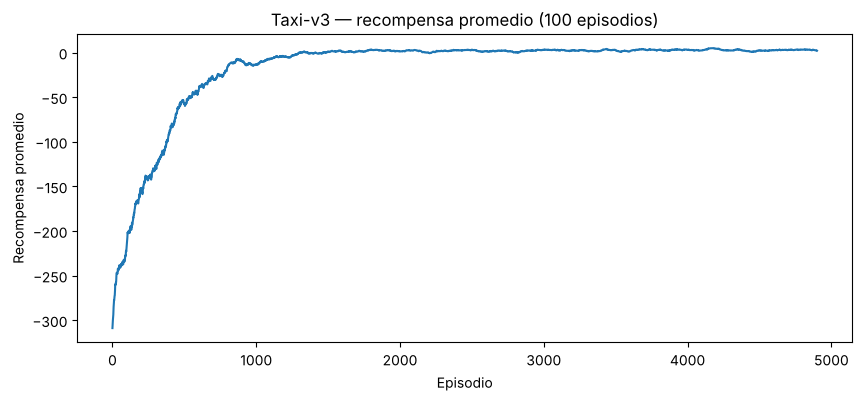

In [9]:
window = 100

moving_average = np.convolve(
    rewards,
    np.ones(window) / window,
    mode="valid"
)

plt.figure(figsize=(10, 4))
plt.plot(moving_average)
plt.xlabel("Episodio")
plt.ylabel("Recompensa promedio")
plt.title(f"Taxi-v3 — recompensa promedio ({window} episodios)")
plt.show()


In [10]:
# Apoyo numérico para la Pregunta 4
print("Media primeros 100 episodios:", np.mean(rewards[:100]))
print("Media episodios 1000-1100   :", np.mean(rewards[1000:1100]))
print("Media últimos 500 episodios :", np.mean(rewards[-500:]), "± ", np.std(rewards[-500:]).round(2))
idx = np.flatnonzero(moving_average >= 0)
print("La media móvil supera 0 por primera vez en el episodio ≈", int(idx[0]) + window if len(idx) else None)


Media primeros 100 episodios: -308.85
Media episodios 1000-1100   : -13.72
Media últimos 500 episodios : 2.648 ±  7.78
La media móvil supera 0 por primera vez en el episodio ≈ 1403


### Pregunta 4

Describa la curva de aprendizaje.

- ¿La recompensa promedio mejora?
- ¿Después de aproximadamente cuántos episodios comienza a estabilizarse?
- ¿El comportamiento observado indica convergencia perfecta o solamente una política razonablemente buena?

**Respuesta** (apoyada en la celda numérica anterior):

- **Sí, mejora mucho.** En los primeros 100 episodios la recompensa media es ≈ **−309**: el taxi deambula hasta el límite de 200 pasos y acumula castigos de −10 por *pickups* y *dropoffs* ilegales. Hacia el episodio 1 000 la media ya es ≈ **−14**.
- La curva sube con fuerza durante los primeros ~1 000 episodios. La media móvil cruza 0 alrededor del episodio **1 400** y a partir de ahí **se estabiliza** cerca de un valor positivo: ≈ **+2.6** en los últimos 500 episodios.
- Indica **una política razonablemente buena, no convergencia perfecta**. La curva sigue con ruido (desviación ≈ 7.8 en los últimos 500 episodios) porque durante el entrenamiento el agente sigue explorando con $\epsilon = 0.1$: una de cada diez acciones es aleatoria y a veces provoca rodeos o castigos de −10. Además, cada episodio parte de una configuración distinta, y el máximo alcanzable depende de lo lejos que estén el pasajero y el destino (≈ +7 a +8 en promedio). Al evaluar **sin exploración** (Experimentación, más abajo) la política greedy completa el 100 % de los episodios con una media de ≈ +8, cerca del óptimo.


## 10. Reproducir un episodio

La siguiente función ejecuta una política greedy usando la Q-table aprendida y guarda los frames del episodio.


In [11]:
def play_episode(env, Q, max_steps=200, seed=None):
    state, _ = env.reset(seed=seed)

    frames = [env.render()]
    total_reward = 0

    for _ in range(max_steps):

        q_values = Q[state]
        max_q = np.max(q_values)

        best_actions = np.flatnonzero(q_values == max_q)
        action = int(np.random.choice(best_actions))

        next_state, reward, terminated, truncated, _ = env.step(action)

        frames.append(env.render())

        total_reward += reward
        state = next_state

        if terminated or truncated:
            break

    return frames, total_reward


def frames_to_video(frames, interval=500):
    fig = plt.figure(figsize=(6, 4))
    plt.axis("off")

    image = plt.imshow(frames[0])

    def update(frame):
        image.set_data(frame)
        return [image]

    anim = animation.FuncAnimation(
        fig,
        update,
        frames=frames,
        interval=interval,
        blit=True,
        repeat=True
    )

    plt.close(fig)
    return HTML(anim.to_jshtml())


## 11. Comparar antes y después

Primero observe un Taxi sin entrenamiento usando una Q-table en cero.


In [12]:
frames_initial, reward_initial = play_episode(
    env,
    Q_initial,
    max_steps=50,
    seed=7
)

print("Recompensa total sin entrenamiento:", reward_initial)
frames_to_video(frames_initial, interval=500)


Recompensa total sin entrenamiento: -158


Ahora observe el agente entrenado.


In [13]:
frames_trained, reward_trained = play_episode(
    env,
    Q_trained,
    max_steps=200,
    seed=7
)

print("Recompensa total después del entrenamiento:", reward_trained)
frames_to_video(frames_trained, interval=500)


Recompensa total después del entrenamiento: 10


### Pregunta 5

Compare los dos episodios.

- ¿Qué diferencias observa en el comportamiento del taxi?
- ¿El taxi sin entrenamiento logra completar la tarea?
- ¿El agente entrenado evita acciones innecesarias?
- ¿Qué evidencia visual le permite afirmar que el agente aprendió?

**Respuesta:**

- **Sin entrenamiento** (Q-table en cero, la política greedy equivale a desempatar al azar): el taxi se mueve sin rumbo, choca contra paredes, vuelve sobre sus pasos e intenta recoger o dejar pasajeros donde no corresponde. Acumula **−158** en 50 pasos (varios castigos de −10). **El agente entrenado** va directo hacia el pasajero, lo recoge, toma la ruta más corta hacia el destino y lo deja, con recompensa total **+10**.
- **No.** El taxi sin entrenamiento no completa la tarea: se le acaban los 50 pasos sin entregar al pasajero.
- **Sí.** El agente entrenado no hace *pickups* ni *dropoffs* ilegales ni movimientos de ida y vuelta. Cada paso lo acerca a su objetivo, y la recompensa final positiva confirma que el número de pasos fue pequeño: $+20$ por la entrega menos 1 por cada movimiento.
- **Evidencia visual:** en la animación entrenada el taxi cambia de color al recoger al pasajero en la parada correcta y el episodio termina al dejarlo en el destino. La trayectoria es corta y sin desvíos. En la animación sin entrenamiento el taxi deambula, el pasajero nunca sube y el episodio se corta por el límite de pasos.


## 12. Analizar la política aprendida

Seleccione un estado cualquiera y observe los valores aprendidos para sus seis acciones.


In [14]:
state = 123

print("Estado:", state)
print("Q-values:", Q_trained[state])
print("Mejor acción:", np.argmax(Q_trained[state]))


Estado: 123
Q-values: [-3.23577723 -2.87153024 -1.90959403  3.94947757 -6.41916212 -5.23005726]
Mejor acción: 3


### Pregunta 6

Para el estado seleccionado:

1. ¿Cuál es la acción con mayor valor Q?
2. ¿Qué significa que una acción tenga un valor Q mayor que otra?
3. ¿Por qué no podemos interpretar $Q(s,a)$ únicamente como la recompensa inmediata de ejecutar la acción?

**Respuesta:**

El estado 123 se decodifica como `env.unwrapped.decode(123) = (1, 1, 0, 3)`: taxi en fila 1, columna 1; pasajero esperando en **R** (esquina superior izquierda); destino **B**.

1. La acción con mayor valor es **3 = West** ($Q \approx 3.95$), seguida de East (≈ −1.91), North (≈ −2.87) y South (≈ −3.24). Pickup (≈ −6.42) y Dropoff (≈ −5.23) son las peores. Tiene sentido: ir al oeste lleva a la columna 0, desde donde el taxi sube a **R** para recoger al pasajero.
2. Que $Q(s,a_1) > Q(s,a_2)$ significa que, **según lo aprendido**, ejecutar $a_1$ y luego actuar de forma óptima produce un **retorno esperado mayor** que hacerlo con $a_2$. La política greedy elegirá $a_1$.
3. Porque $Q$ incluye el **futuro**: $Q(s,a)=\mathbb{E}[r_{t+1}+\gamma\max_{a'}Q(s_{t+1},a')]$. La recompensa inmediata de *cualquier* movimiento es la misma (−1), y aun así West vale +3.95 y South −3.24. La diferencia está en lo que viene después: West deja al taxi más cerca de completar la entrega (+20). Pickup y Dropoff valen −6 y −5 porque aquí son ilegales y dan −10 de inmediato, aunque el futuro amortigua un poco ese castigo.


## 13. Experimentación

Modifique **solo uno** de los siguientes hiperparámetros y vuelva a entrenar:

- $\alpha$
- $\gamma$
- $\epsilon$

**Hiperparámetro modificado:** $\epsilon$, de **0.1 a 0.4**. Se mantienen $\alpha=0.1$, $\gamma=0.95$, 5 000 episodios y la misma semilla (ver la celda siguiente).

### Pregunta 7

Compare el nuevo entrenamiento con el original.

Explique cómo el cambio del hiperparámetro afectó:

- velocidad de aprendizaje,
- estabilidad,
- recompensa final,
- comportamiento observado.

**Respuesta** (resultados de la celda siguiente):

- **Velocidad de aprendizaje:** al principio ambas curvas suben a un ritmo parecido, porque más exploración ayuda a visitar más pares $(s,a)$ desde el inicio. Pero con $\epsilon=0.4$ la curva de entrenamiento se queda estancada mucho más abajo: **nunca** alcanza una media móvil positiva, mientras que con $\epsilon=0.1$ cruza 0 hacia el episodio 1 400.
- **Estabilidad:** empeora claramente. La desviación de la recompensa en los últimos 500 episodios pasa de ≈ **7.8** a ≈ **24.1**. Con un 40 % de acciones al azar, muchos episodios incluyen rodeos largos y castigos de −10 por *pickups*/*dropoffs* ilegales.
- **Recompensa final:** durante el entrenamiento la media de los últimos 500 episodios cae de ≈ **+2.6** a ≈ **−28.6**. Sin embargo, **al evaluar la política greedy** (sin exploración), ambas Q-tables logran **100 % de éxito y la misma media (≈ +7.96)**. La política aprendida es igual de buena; lo que empeora es el desempeño *mientras se entrena*.
- **Comportamiento observado:** con $\epsilon=0.4$ el taxi en entrenamiento se ve errático: avanza, hace un movimiento aleatorio que lo aleja y debe corregir. Taxi es determinístico y relativamente pequeño, así que con 5 000 episodios incluso $\epsilon=0.1$ explora lo suficiente para encontrar la política óptima. Subir $\epsilon$ solo añade "costo de exploración" sin mejorar el resultado final. Lo ideal sería un $\epsilon$ que decaiga con el tiempo, como en FrozenLake: mucha exploración al inicio y casi nada al final.


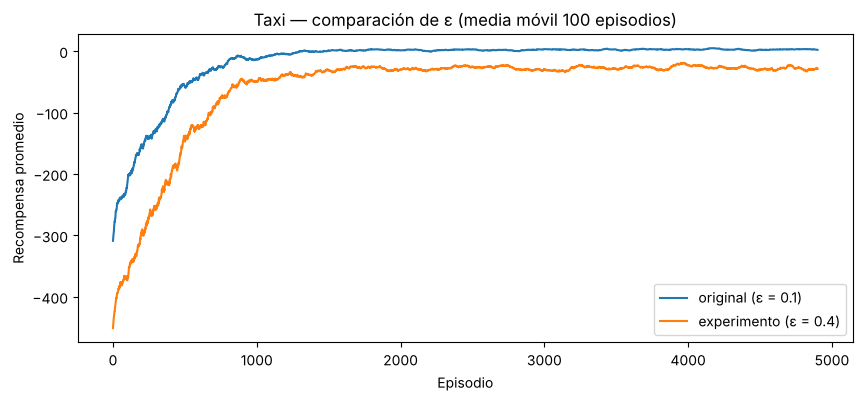

ε = 0.1: media últimos 500 ep. (entrenando) =    2.65 | desv. =  7.78 | MA≥0 en episodio ≈ 1403 | evaluación greedy: media =   7.96, éxito = 100%
ε = 0.4: media últimos 500 ep. (entrenando) =  -28.60 | desv. = 24.11 | MA≥0 en episodio ≈ None | evaluación greedy: media =   7.96, éxito = 100%


In [15]:
# Experimento: se modifica SOLO epsilon (0.1 -> 0.4); alpha y gamma se mantienen
random.seed(SEED); np.random.seed(SEED)
env.action_space.seed(SEED); env.reset(seed=SEED)

Q_exp, rewards_exp = train_q_learning(
    env,
    np.zeros((n_states, n_actions)),
    episodes=5000,
    alpha=0.1,
    gamma=0.95,
    epsilon=0.4
)

ma_exp = np.convolve(rewards_exp, np.ones(window) / window, mode="valid")

plt.figure(figsize=(10, 4))
plt.plot(moving_average, label="original (ε = 0.1)")
plt.plot(ma_exp, label="experimento (ε = 0.4)")
plt.xlabel("Episodio")
plt.ylabel("Recompensa promedio")
plt.title(f"Taxi — comparación de ε (media móvil {window} episodios)")
plt.legend()
plt.show()

def evaluar_greedy(env, Q, n=200, max_steps=200):
    """Evalúa la política greedy (sin exploración) en n episodios."""
    totales, exitos = [], 0
    for i in range(n):
        s, _ = env.reset(seed=1000 + i)
        tot = 0
        for _ in range(max_steps):
            s, r, term, trunc, _ = env.step(int(np.argmax(Q[s])))
            tot += r
            if term or trunc:
                exitos += int(term)
                break
        totales.append(tot)
    return np.mean(totales), exitos / n

def primer_episodio_estable(ma, umbral=0.0):
    idx = np.flatnonzero(ma >= umbral)
    return int(idx[0]) + window if len(idx) else None

for nombre, rw, Qx, ma in [("ε = 0.1", rewards, Q_trained, moving_average),
                          ("ε = 0.4", rewards_exp, Q_exp, ma_exp)]:
    m, ex = evaluar_greedy(env, Qx)
    print(f"{nombre}: media últimos 500 ep. (entrenando) = {np.mean(rw[-500:]):7.2f} | "
          f"desv. = {np.std(rw[-500:]):5.2f} | MA≥0 en episodio ≈ {primer_episodio_estable(ma)} | "
          f"evaluación greedy: media = {m:6.2f}, éxito = {ex:.0%}")


## Entrega

El notebook debe contener:

1. implementación de `choose_action`;
2. implementación de `update_q`;
3. implementación de `train_q_learning`;
4. curva de aprendizaje;
5. visualización del agente antes y después del entrenamiento;
6. respuestas a las siete preguntas.

No es necesario modificar las funciones auxiliares de visualización.
